# 03 ClubElo

**Owner:** Devarshi

Club strength at entry = ClubElo rating of the player's FIFA club on the edition date (CLAUDE.md §6). Missing means
the club is not rated (non-European club, a country or tier outside the snapshot, a reserve side). Missing values are
flagged and never imputed.

**Snapshots:** `src.clubelo.load_best_snapshots` uses an API snapshot (`clubelo_YYYY-MM-DD.csv`) if one is cached,
otherwise the mirror snapshot (`clubelo_mirror_YYYY-MM-DD.csv`, Kaggle *Club Football Match Data (2000–2025)* by adamgbor,
Elo data from ClubElo; see `DECISIONS.md`). Only the four cohort entry dates are needed.

**Mapping:** FIFA `club_name` → ClubElo club within the same country. Order: reserve/B sides are never mapped →
`data/manual/club_name_overrides.csv` → a unique ClubElo name whose words all appear in the FIFA name ("West Brom" in
"West Bromwich Albion") → fuzzy match ≥ 90 with a 5-point lead. Every European club with 3+ cohort players must end up
mapped or explicitly not rated.

**Known gaps (left blank, never estimated):** clubs in Switzerland, Ireland, Ukraine and Czechia (not in the mirror),
and English League One / League Two (not rated by ClubElo).

**Outputs:** `data/clean/clubelo_by_edition.parquet`, `data/clean/club_strength.parquet` (one row per cohort entrant),
section `03` of `reports/data_quality.md`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config, dq, clubelo, clubs

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 200)

CHECKS, NOTES = [], []
def check(name, passed, detail=""):
    CHECKS.append({"Check": name, "Result": "PASS" if passed else "FAIL", "Detail": detail})
    print(("PASS" if passed else "FAIL"), "-", name, ("| " + detail if detail else ""))
    return passed

ENTRY_DATES = {e: config.EXPECTED_EDITION_DATES[e] for e in config.COHORT_EDITIONS}

## 1. Snapshots

In [2]:
all_dates = list(config.EXPECTED_EDITION_DATES.values())
snaps = clubelo.load_best_snapshots(all_dates)
src_tbl = pd.DataFrame([{"Edition": config.EDITION_LABELS[e], "Date": d,
                         "Source": (snaps[d]["source"].iat[0] if d in snaps else "missing"),
                         "Rating date": (snaps[d]["rating_date"].iat[0] if d in snaps and "rating_date" in snaps[d] else (d if d in snaps else "")),
                         "Clubs": (len(snaps[d]) if d in snaps else None)} for e, d in config.EXPECTED_EDITION_DATES.items()])
display(src_tbl)
missing_entry = [d for d in ENTRY_DATES.values() if d not in snaps]
check("A snapshot exists for each of the 4 cohort entry dates", not missing_entry, f"missing: {missing_entry}")
assert not missing_entry, "Build the mirror snapshots (scripts/build_clubelo_mirror.py) or wait for the API."
api_used = [d for d in ENTRY_DATES.values() if snaps[d]["source"].iat[0] == "api"]
if api_used:
    NOTES.append(f"API snapshots used for {api_used}. Club names differ between API and mirror; check the overrides.")
print("API snapshots used for entry dates:", api_used or "none (mirror)")

rows = []
for e, d in config.EXPECTED_EDITION_DATES.items():
    if d in snaps:
        s = snaps[d]
        rows.append(pd.DataFrame({"club": s["team"], "country": s["country"], "level": s["level"], "elo": s["elo"],
                                  "edition": e, "edition_label": config.EDITION_LABELS[e], "snapshot_date": d,
                                  "rating_date": s["rating_date"] if "rating_date" in s else d, "source": s["source"]}))
by_ed = pd.concat(rows, ignore_index=True)
check("No duplicate club within a snapshot", not by_ed.duplicated(["edition", "club", "country"]).any())
check("Elo values in a plausible range (1000–2300)", bool(by_ed["elo"].between(1000, 2300).all()),
      f"{by_ed['elo'].min():.0f}–{by_ed['elo'].max():.0f}")
for d in ENTRY_DATES.values():
    s = by_ed[by_ed["snapshot_date"] == d].nlargest(5, "elo")
    print(d, "top 5:", ", ".join(f"{c} {x:.0f}" for c, x in zip(s["club"], s["elo"])))
by_ed.to_parquet(config.CLEAN / "clubelo_by_edition.parquet", index=False)
print("clubelo_by_edition.parquet:", by_ed.shape)

,Edition,Date,Source,Rating date,Clubs
0,FIFA 15,2014-09-18,mirror: Kaggle adamgbor/club-football-match-da...,2014-09-15,415.0
1,FIFA 16,2015-09-21,mirror: Kaggle adamgbor/club-football-match-da...,2015-09-15,406.0
2,FIFA 17,2016-09-20,mirror: Kaggle adamgbor/club-football-match-da...,2016-09-15,409.0
3,FIFA 18,2017-09-18,mirror: Kaggle adamgbor/club-football-match-da...,2017-09-15,408.0
4,FIFA 19,2018-08-21,missing,,NaN
5,FIFA 20,2019-09-19,missing,,NaN
6,FIFA 21,2020-09-23,missing,,NaN
7,FIFA 22,2021-09-23,missing,,NaN
8,FIFA 23,2022-09-26,missing,,NaN
9,FC 24,2023-09-22,missing,,NaN


PASS - A snapshot exists for each of the 4 cohort entry dates | missing: []
API snapshots used for entry dates: none (mirror)
PASS - No duplicate club within a snapshot 
PASS - Elo values in a plausible range (1000–2300) | 1116–2101
2014-09-18 top 5: Real Madrid 2041, Barcelona 2031, Bayern Munich 2030, Ath Madrid 1980, Man City 1947
2015-09-21 top 5: Barcelona 2101, Real Madrid 2067, Bayern Munich 1997, Ath Madrid 1958, Man City 1909
2016-09-20 top 5: Real Madrid 2082, Barcelona 2050, Bayern Munich 2014, Ath Madrid 2000, Juventus 1925
2017-09-18 top 5: Real Madrid 2077, Barcelona 2044, Bayern Munich 1969, Ath Madrid 1955, Juventus 1954
clubelo_by_edition.parquet: (1638, 9)


## 2. ClubElo name universe
Names a FIFA club can map to: every ClubElo club in the same country in the entry-date snapshots, plus (for the mirror)
every club the mirror rated between July 2014 and June 2018, so a club outside the snapshot on one date (relegated that
season) still maps by name and simply has no Elo on that date.

In [3]:
universe = by_ed[by_ed["snapshot_date"].isin(ENTRY_DATES.values())][["club", "country"]]
if any(snaps[d]["source"].iat[0] != "api" for d in ENTRY_DATES.values()):
    mr = pd.read_csv(clubelo.MIRROR_DIR / "EloRatings.csv", parse_dates=["date"])
    universe = pd.concat([universe, mr[mr["date"].between("2014-07-01", "2018-06-30")][["club", "country"]]])
universe = universe.drop_duplicates()
names_by_country = universe.groupby("country")["club"].apply(list).to_dict()
snapshot_countries = set(by_ed.loc[by_ed["snapshot_date"].isin(ENTRY_DATES.values()), "country"])
print(f"{len(universe):,} ClubElo names in {len(snapshot_countries)} countries:", sorted(snapshot_countries))

550 ClubElo names in 19 countries: ['AUT', 'BEL', 'DEN', 'ENG', 'ESP', 'FIN', 'FRA', 'GER', 'GRE', 'ITA', 'NED', 'NOR', 'POL', 'POR', 'ROM', 'RUS', 'SCO', 'SWE', 'TUR']


## 3. FIFA clubs of cohort entrants

In [4]:
coh = pd.read_parquet(config.CLEAN / "cohort.parquet")
coh["clubelo_country"] = coh["league_country"].map(clubs.CLUBELO_COUNTRY)
fc = (coh.dropna(subset=["club_team_id"])
         .groupby(["club_team_id", "club_name"], as_index=False)
         .agg(league_country=("league_country", "first"), clubelo_country=("clubelo_country", "first"),
              cohort_n=("player_id", "size"), cohort_n75=("potential", lambda s: int((s >= 75).sum())),
              min_level=("league_level", "min")))
check("Each FIFA club id has one name and one country",
      fc["club_team_id"].is_unique, f"{int(fc['club_team_id'].duplicated().sum())} duplicates")
fc["european"] = fc["league_country"].isin(clubs.EUROPEAN_LEAGUE_COUNTRIES)
fc["in_snapshot_country"] = fc["clubelo_country"].isin(snapshot_countries)
fc["reserve"] = fc["club_name"].map(clubs.is_reserve)
print(f"FIFA clubs: {len(fc):,}; European: {int(fc['european'].sum())}; in snapshot countries: {int(fc['in_snapshot_country'].sum())}")
print("Reserve sides (never mapped):", fc.loc[fc["reserve"], "club_name"].tolist())

PASS - Each FIFA club id has one name and one country | 0 duplicates
FIFA clubs: 766; European: 560; in snapshot countries: 530
Reserve sides (never mapped): ['SV Werder Bremen II', 'Athletic Club de Bilbao B', 'FC Barcelona B', 'Sevilla Atlético']


## 4. Map clubs: overrides, then rules

In [5]:
ov = pd.read_csv(config.CLUB_NAME_OVERRIDES, dtype={"clubelo_club": str, "note": str, "reviewer": str})
ov["fifa_club_id"] = ov["fifa_club_id"].astype("Int64")
ov["clubelo_club"] = ov["clubelo_club"].fillna("")
check("Override file lists each FIFA club once", ov["fifa_club_id"].is_unique)
check("Override status is 'mapped' or 'not_in_clubelo'", ov["status"].isin(["mapped", "not_in_clubelo"]).all())
known = set(zip(universe["club"], universe["country"]))
bad = ov[(ov["status"] == "mapped") & ~pd.Series(list(zip(ov["clubelo_club"], ov["clubelo_country"]))).isin(known).values]
check("Every mapped override names a ClubElo club in the universe", bad.empty, f"{bad['fifa_club'].tolist()}")
ovi = ov.set_index("fifa_club_id")

res = []
for r in fc.itertuples(index=False):
    if r.reserve:
        res.append((None, "reserve side (not rated)", None))
    elif r.club_team_id in ovi.index:
        o = ovi.loc[r.club_team_id]
        res.append(((o["clubelo_club"] or None), "override" if o["status"] == "mapped" else "override: not in ClubElo", None))
    elif not r.in_snapshot_country:
        res.append((None, "country not in snapshots", None))
    else:
        team, method, sc, _ = clubs.resolve(r.club_name, names_by_country.get(r.clubelo_country, []))
        res.append((team, method, sc))
fc[["clubelo_club", "map_method", "map_score"]] = pd.DataFrame(res, index=fc.index)
display(fc["map_method"].value_counts().to_frame("clubs"))

# A ClubElo club may belong to one FIFA club only
mapped = fc.dropna(subset=["clubelo_club"])
dupe = mapped[mapped.duplicated(["clubelo_club", "clubelo_country"], keep=False)].sort_values("clubelo_club")
check("No ClubElo club is claimed by two FIFA clubs", dupe.empty, "; ".join(f"{a} -> {b}" for a, b in zip(dupe["club_name"], dupe["clubelo_club"])))
display(dupe[["club_team_id", "club_name", "clubelo_club", "map_method"]])

PASS - Override file lists each FIFA club once 
PASS - Override status is 'mapped' or 'not_in_clubelo' 
PASS - Every mapped override names a ClubElo club in the universe | []


,clubs
map_method,
subset,421
country not in snapshots,236
unmapped,58
override,31
fuzzy,15
reserve side (not rated),4
override: not in ClubElo,1


PASS - No ClubElo club is claimed by two FIFA clubs 


,club_team_id,club_name,clubelo_club,map_method


In [6]:
# Every European club in a snapshot country with 3+ cohort players: mapped, or explicitly not rated.
# A club that maps to nothing and played below the second tier at entry is marked "lower tier (not rated)".
lower = fc["clubelo_club"].isna() & fc["map_method"].isin(["unmapped", "ambiguous"]) & (fc["min_level"] >= 3)
fc.loc[lower, "map_method"] = "lower tier (not rated)"
need = fc[fc["in_snapshot_country"] & (fc["cohort_n"] >= config.CLUB_MIN_COHORT_PLAYERS)]
open_ = need[need["map_method"].isin(["unmapped", "ambiguous"])]
check(f"Every European club with {config.CLUB_MIN_COHORT_PLAYERS}+ cohort players is mapped or marked not rated",
      open_.empty, f"{len(open_)} open: {open_['club_name'].tolist()[:15]}")
display(open_[["club_team_id", "club_name", "clubelo_country", "min_level", "cohort_n", "map_score"]])
small_open = fc[fc["in_snapshot_country"] & fc["map_method"].isin(["unmapped", "ambiguous"])]
print(f"Unmapped clubs with fewer than {config.CLUB_MIN_COHORT_PLAYERS} cohort players (allowed): {len(small_open)}")
display(small_open[["club_name", "clubelo_country", "min_level", "cohort_n"]].head(20))

PASS - Every European club with 3+ cohort players is mapped or marked not rated | 0 open: []


,club_team_id,club_name,clubelo_country,min_level,cohort_n,map_score


Unmapped clubs with fewer than 3 cohort players (allowed): 0


,club_name,clubelo_country,min_level,cohort_n


### Spot check: rule-based matches whose names differ

In [7]:
diff = fc[fc["map_method"].isin(["subset", "fuzzy"]) & (fc["club_name"].map(clubs.club_key) != fc["clubelo_club"].fillna("").map(clubs.club_key))]
print(f"{len(diff)} rule matches with different normalised names (all listed for review):")
print("; ".join(f"{a} -> {b}" for a, b in zip(diff["club_name"], diff["clubelo_club"])))

129 rule matches with different normalised names (all listed for review):
Blackburn Rovers -> Blackburn; Bolton Wanderers -> Bolton; Leeds United -> Leeds; Newcastle United -> Newcastle; Tottenham Hotspur -> Tottenham; West Ham United -> West Ham; Borussia Dortmund -> Dortmund; Borussia Mönchengladbach -> MGladbach; Bayer 04 Leverkusen -> Leverkusen; Birmingham City -> Birmingham; Charlton Athletic -> Charlton; Derby County -> Derby; Ipswich Town -> Ipswich; Leicester City -> Leicester; West Bromwich Albion -> West Brom; Doncaster Rovers -> Doncaster; DSC Arminia Bielefeld -> Bielefeld; VfL Bochum 1848 -> Bochum; Hertha BSC -> Hertha; Hamilton Academical -> Hamilton; Hellas Verona -> Verona; Olympique de Marseille -> Marseille; Standard Liège -> Standard; Deportivo de La Coruña -> La Coruna; Real Zaragoza -> Zaragoza; LASK Linz -> LASK; AEK Athens -> AEK; Olympiakos Piraeus -> Olympiakos; Yeovil Town -> Yeovil; Stade de Reims -> Reims; Górnik Zabrze -> Gornik; Real Betis -> Betis; Celt

## 5. Club strength at entry (one row per cohort entrant)

In [8]:
ent = coh[["player_id", "short_name", "entry_edition", "entry_edition_label", "potential", "potential_band",
           "club_team_id", "club_name", "league_name_edition", "league_level", "league_country", "clubelo_country"]].copy()
ent = ent.merge(fc[["club_team_id", "clubelo_club", "map_method", "european", "in_snapshot_country"]], on="club_team_id", how="left")
ent["entry_date"] = ent["entry_edition"].map(ENTRY_DATES)
snap_e = by_ed[by_ed["snapshot_date"].isin(ENTRY_DATES.values())][["snapshot_date", "club", "country", "elo", "rating_date", "source"]]
ent = ent.merge(snap_e.rename(columns={"snapshot_date": "entry_date", "club": "clubelo_club", "country": "clubelo_country",
                                       "elo": "club_elo_at_entry", "rating_date": "clubelo_rating_date", "source": "clubelo_source"}),
                on=["entry_date", "clubelo_club", "clubelo_country"], how="left")

eng_l1l2 = (ent["league_country"] == "England") & ent["league_name_edition"].isin(["League One", "League Two"])
conds = [
    ent["club_elo_at_entry"].notna(),
    ent["club_name"].isna(),
    ~ent["european"].fillna(False).astype(bool),
    ~ent["in_snapshot_country"].fillna(False).astype(bool),
    eng_l1l2,
    ent["map_method"].eq("reserve side (not rated)"),
    ent["map_method"].isin(["lower tier (not rated)", "override: not in ClubElo"]),
    ent["clubelo_club"].notna(),
]
labels = ["Elo at entry", "No club", "Outside Europe", "Known gap: country not in mirror",
          "Known gap: English League One/Two", "Reserve side (not rated)", "Not rated: lower tier",
          "Mapped, not rated on entry date"]
ent["club_strength_status"] = np.select(conds, labels, default="Unmapped")
ent["non_european_club"] = ent["club_strength_status"].eq("Outside Europe")
ent.loc[ent["club_strength_status"] != "Elo at entry", "club_elo_at_entry"] = np.nan
check("club_strength: one row per cohort entrant", len(ent) == len(coh) and ent["player_id"].is_unique)
check("No Elo for a non-European club", ent.loc[ent["non_european_club"], "club_elo_at_entry"].isna().all())

status_all = ent["club_strength_status"].value_counts().to_frame("entrants")
status_all["%"] = (status_all["entrants"] / len(ent) * 100).round(1)
display(status_all)

PASS - club_strength: one row per cohort entrant 
PASS - No Elo for a non-European club 


,entrants,%
club_strength_status,,
Elo at entry,7326,63.6
Outside Europe,2351,20.4
Known gap: English League One/Two,1074,9.3
Known gap: country not in mirror,499,4.3
Reserve side (not rated),96,0.8
Not rated: lower tier,88,0.8
No club,59,0.5
"Mapped, not rated on entry date",26,0.2


## 6. Coverage for entrants with potential ≥ 75
Target: ≥ 90% of entrants at clubs in countries the mirror covers have an Elo, with English League One/Two excluded
as a known gap.

In [9]:
p75 = ent[ent["potential"] >= 75]
st75 = p75["club_strength_status"].value_counts().to_frame("entrants")
st75["% of potential-75+"] = (st75["entrants"] / len(p75) * 100).round(1)
display(st75)

denom = p75[p75["in_snapshot_country"].fillna(False).astype(bool) & ~p75["club_strength_status"].eq("Known gap: English League One/Two")
            & p75["club_name"].notna()]
cov = denom["club_strength_status"].eq("Elo at entry").mean()
by_band = (denom.groupby("potential_band", observed=True)["club_strength_status"]
                .agg(entrants="size", with_elo=lambda s: int((s == "Elo at entry").sum())))
by_band["coverage_%"] = (by_band["with_elo"] / by_band["entrants"] * 100).round(1)
by_band.index = by_band.index.astype(str)
by_band.loc["All 75+"] = [len(denom), int(denom["club_strength_status"].eq("Elo at entry").sum()), round(cov * 100, 1)]
display(by_band)
overall_75 = p75["club_strength_status"].eq("Elo at entry").mean()
print(f"Share of ALL potential-75+ entrants with an Elo at entry: {overall_75:.1%} (of {len(p75):,})")
check("Coverage >= 90% for potential-75+ entrants at clubs in mirror countries (excl. English League One/Two)",
      cov >= 0.90, f"{cov:.1%} of {len(denom):,}")

miss = denom[denom["club_strength_status"] != "Elo at entry"]
print("Remaining misses in the denominator, by reason and club:")
display(miss.groupby(["club_strength_status", "club_name"]).size().sort_values(ascending=False).head(25).to_frame("entrants"))
gaps = p75[p75["club_strength_status"].str.startswith("Known gap")].groupby(["club_strength_status", "league_country"]).size()
print("Known gaps among potential-75+ entrants:"); display(gaps.to_frame("entrants"))

,entrants,% of potential-75+
club_strength_status,,
Elo at entry,1981,79.6
Outside Europe,333,13.4
Known gap: English League One/Two,62,2.5
Reserve side (not rated),48,1.9
Known gap: country not in mirror,41,1.6
No club,16,0.6
Not rated: lower tier,6,0.2
"Mapped, not rated on entry date",1,0.0


,entrants,with_elo,coverage_%
potential_band,,,
75–79,1420,1384,97.5
80–84,516,501,97.1
85+,100,96,96.0
All 75+,2036,1981,97.3


Share of ALL potential-75+ entrants with an Elo at entry: 79.6% (of 2,488)
PASS - Coverage >= 90% for potential-75+ entrants at clubs in mirror countries (excl. English League One/Two) | 97.3% of 2,036
Remaining misses in the denominator, by reason and club:


entrants
club_strength_status            club_name                          
Reserve side (not rated)        FC Barcelona B                   20
                                Athletic Club de Bilbao B        12
                                Sevilla Atlético                 12
                                SV Werder Bremen II               4
Mapped, not rated on entry date VfR Aalen                         1
Not rated: lower tier           FC Rot-Weiß Erfurt                1
                                Hansa Rostock                     1
                                Magdeburg                         1
                                Preußen Münster                   1
                                SG Sonnenhof Großaspach           1
                                Wehen Wiesbaden                   1

Known gaps among potential-75+ entrants:


entrants
club_strength_status              league_country               
Known gap: English League One/Two England                    62
Known gap: country not in mirror  Czech Republic              2
                                  Republic of Ireland         2
                                  Switzerland                32
                                  Ukraine                     5

## 7. Save

club_strength.parquet: (11519, 17)


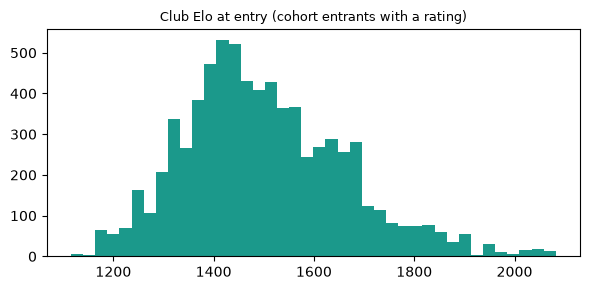

In [10]:
cs = ent[["player_id", "entry_edition", "entry_edition_label", "entry_date", "club_team_id", "club_name",
          "league_name_edition", "league_level", "league_country", "clubelo_country", "clubelo_club", "map_method",
          "club_elo_at_entry", "clubelo_rating_date", "clubelo_source", "club_strength_status", "non_european_club"]]
cs.to_parquet(config.CLEAN / "club_strength.parquet", index=False)
print("club_strength.parquet:", cs.shape)

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(cs["club_elo_at_entry"].dropna(), bins=40, color=config.PALETTE["reality"])
ax.set_title("Club Elo at entry (cohort entrants with a rating)", fontsize=9)
plt.tight_layout(); plt.show()

## 8. Write to `reports/data_quality.md`

In [11]:
checks = pd.DataFrame(CHECKS)
body = f'''
### Snapshots used

{dq.df_to_md(src_tbl)}

### Club mapping

{dq.df_to_md(fc["map_method"].value_counts().rename_axis("Method").reset_index(name="FIFA clubs"))}

Rule matches whose normalised names differ ({len(diff)}, for review): {"; ".join(f"{a} → {b}" for a, b in zip(diff["club_name"], diff["clubelo_club"]))}

### Club strength status, all cohort entrants

{dq.df_to_md(status_all.rename_axis("Status").reset_index())}

### Coverage, potential ≥ 75

Denominator: potential-75+ entrants at clubs in countries the snapshots cover, excluding English League One/Two (known gap).
Coverage: **{cov:.1%}** of {len(denom):,}. Share of all {len(p75):,} potential-75+ entrants with an Elo: {overall_75:.1%}.

{dq.df_to_md(by_band.rename_axis("Band").reset_index())}

{dq.df_to_md(st75.rename_axis("Status").reset_index())}

### Notes

{chr(10).join("- " + n for n in NOTES) if NOTES else "- none"}

### Checks

{dq.df_to_md(checks)}
'''
dq.write_section("03", "03 ClubElo", body)
print("Written to", config.DATA_QUALITY.relative_to(ROOT))

Written to reports/data_quality.md


## 9. Summary

In [12]:
display(checks)
for n in NOTES:
    print(" -", n)
assert (checks["Result"] == "PASS").all(), checks[checks["Result"] == "FAIL"]

,Check,Result,Detail
0,A snapshot exists for each of the 4 cohort ent...,PASS,missing: []
1,No duplicate club within a snapshot,PASS,
2,Elo values in a plausible range (1000–2300),PASS,1116–2101
3,Each FIFA club id has one name and one country,PASS,0 duplicates
4,Override file lists each FIFA club once,PASS,
5,Override status is 'mapped' or 'not_in_clubelo',PASS,
6,Every mapped override names a ClubElo club in ...,PASS,[]
7,No ClubElo club is claimed by two FIFA clubs,PASS,
8,Every European club with 3+ cohort players is ...,PASS,0 open: []
9,club_strength: one row per cohort entrant,PASS,
